# 04 · Ajuste de hiperparámetros de los 3 mejores candidatos

**Quiénes entran.** Los tres mejores candidatos *entrenables* por WAPE en CV: Ridge, MLP y RandomForest (se leen de MLflow, no se copian a mano). Chronos-2 y el LLM quedan fuera: no tienen pesos que ajustar a estos datos (son *zero-shot*), y lo que podría variarse en ellos (la longitud del contexto o el prompt) no es un espacio de hiperparámetros comparable.

**Por qué Optuna (TPE) y no RandomizedSearchCV.** Con un presupuesto fijo de 30 configuraciones, TPE concentra las pruebas en las regiones que ya rindieron bien, mientras que la búsqueda aleatoria las reparte a ciegas. Además, Optuna maneja escalas logarítmicas y espacios condicionales, y su muestreador con semilla hace que la búsqueda sea reproducible. Cada configuración se evalúa con **la misma CV temporal** (`P.evaluar`) y se registra como **corrida hija** dentro de una corrida padre por modelo.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="mlflow")   # avisos de esquema de MLflow
import os, logging
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT", "1")
logging.getLogger("mlflow").setLevel(logging.ERROR)   # avisos repetidos de serialización/entorno
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import optuna
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

import src.pipeline as P
import src.tracking as T
from src.datos import cargar_obt
from src import estilo
estilo.aplicar()
optuna.logging.set_verbosity(optuna.logging.WARNING)

T.configurar()
snap = cargar_obt()
div = P.dividir(P.agregar_features(snap.datos))
pliegues = P.pliegues_temporales(div.train)
N_TRIALS = 30

In [2]:
# Los 3 mejores candidatos entrenables, leídos de MLflow.
cand = mlflow.search_runs(filter_string="tags.fase = 'candidato'", order_by=["metrics.cv_wape_mean ASC"])
cand = cand[~cand["tags.familia"].isin(["fundacional", "llm"])]
top3 = cand.head(3)[["tags.mlflow.runName", "tags.familia", "metrics.cv_wape_mean", "metrics.cv_wape_std", "run_id"]]
top3

,tags.mlflow.runName,tags.familia,metrics.cv_wape_mean,metrics.cv_wape_std,run_id
0,ridge,lineal_regularizado,0.379363,0.035370,6b1e7dac12dd4d31bdbab9716019b1d4
1,mlp,red_neuronal,0.392319,0.042772,19665330e867498f916197d6f496498f
3,random_forest,bagging,0.410175,0.028147,9a26dec77bbd473f90e8bae2ed6caebe


## Espacios de búsqueda

| Modelo | Hiperparámetro | Rango | Escala | Justificación |
|---|---|---|---|---|
| Ridge | `alpha` | 1e-2 – 1e3 | log | La regularización actúa por órdenes de magnitud |
| Ridge | transformación del target | ninguna, log1p, raíz | categórica | H1: target de conteo sobredisperso |
| MLP | capas ocultas | (16), (32), (64), (32,16), (64,32) | categórica | Con ~700 filas, redes pequeñas; más capacidad sobreajusta |
| MLP | `alpha` (L2) | 1e-5 – 10 | log | Igual que en Ridge |
| MLP | `learning_rate_init` | 1e-4 – 3e-2 | log | La tasa de aprendizaje se mueve en escala multiplicativa |
| MLP | `batch_size` | 16, 32, 64 | categórica | Lotes chicos = más actualizaciones con pocos datos |
| MLP | `max_iter` | 200 – 2000 | lineal (paso 100) | La MLP por defecto no convergía en 200 |
| MLP | activación | relu, tanh | categórica | |
| RandomForest | `n_estimators` | 100 – 800 | lineal (paso 50) | Más árboles solo reducen varianza; no sobreajustan |
| RandomForest | `max_depth` | 3 – 30 o sin límite | log | El modelo por defecto memoriza (brecha 0,27): limitar la profundidad |
| RandomForest | `min_samples_leaf` | 1 – 40 | log | Hojas más grandes = predicciones más suaves |
| RandomForest | `max_features` | sqrt, 0.3, 0.5, 0.8, 1.0 | categórica | Decorrelaciona los árboles |

No se usa `early_stopping` en la MLP: separaría una validación **aleatoria**, que en una serie temporal filtraría información del futuro.

In [3]:
def ridge(trial):
    t = trial.suggest_categorical("transformacion_target", ["ninguna", "log1p", "raiz"])
    est = Ridge(alpha=trial.suggest_float("alpha", 1e-2, 1e3, log=True))
    if t == "log1p":
        est = TransformedTargetRegressor(est, func=np.log1p, inverse_func=np.expm1)
    elif t == "raiz":
        est = TransformedTargetRegressor(est, func=np.sqrt, inverse_func=np.square)
    return P.construir_pipeline(est)

CAPAS = {"16": (16,), "32": (32,), "64": (64,), "32-16": (32, 16), "64-32": (64, 32)}
def mlp(trial):
    return P.construir_pipeline(MLPRegressor(
        hidden_layer_sizes=CAPAS[trial.suggest_categorical("capas", list(CAPAS))],
        alpha=trial.suggest_float("alpha", 1e-5, 10, log=True),
        learning_rate_init=trial.suggest_float("learning_rate_init", 1e-4, 3e-2, log=True),
        batch_size=trial.suggest_categorical("batch_size", [16, 32, 64]),
        max_iter=trial.suggest_int("max_iter", 200, 2000, step=100),
        activation=trial.suggest_categorical("activation", ["relu", "tanh"]),
        random_state=P.SEMILLA))

def random_forest(trial):
    sin_limite = trial.suggest_categorical("sin_limite_profundidad", [False, True])
    return P.construir_pipeline(RandomForestRegressor(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        max_depth=None if sin_limite else trial.suggest_int("max_depth", 3, 30, log=True),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 40, log=True),
        max_features=trial.suggest_categorical("max_features", ["sqrt", 0.3, 0.5, 0.8, 1.0]),
        random_state=P.SEMILLA, n_jobs=-1))

ESPACIOS = {"ridge": (ridge, "lineal_regularizado"), "mlp": (mlp, "red_neuronal"),
            "random_forest": (random_forest, "bagging")}

In [4]:
def tunear(nombre):
    construir, familia = ESPACIOS[nombre]
    base = top3.set_index("tags.mlflow.runName").loc[nombre]
    historial = []
    with mlflow.start_run(run_name=f"tuning_{nombre}") as padre:
        def objetivo(trial):
            modelo = construir(trial)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = P.evaluar(modelo, div.train, pliegues)
            run_id = T.registrar(f"{nombre}_trial_{trial.number:02d}", modelo, res, fase="tuning",
                                 familia=familia, snapshot=snap, train=div.train,
                                 params_extra={f"optuna_{k}": v for k, v in trial.params.items()}, nested=True)
            historial.append({"trial": trial.number, **trial.params, **res.metricas, "run_id": run_id,
                              "pliegues": res.wape_pliegues})
            return res.metricas["cv_wape_mean"]

        estudio = optuna.create_study(direction="minimize", study_name=nombre,
                                      sampler=optuna.samplers.TPESampler(seed=P.SEMILLA, n_startup_trials=10))
        estudio.optimize(objetivo, n_trials=N_TRIALS)

        h = pd.DataFrame(historial)
        mejor = h.loc[h.cv_wape_mean.idxmin()]
        mejora = base["metrics.cv_wape_mean"] - mejor.cv_wape_mean
        mlflow.log_params({f"mejor_{k}": v for k, v in estudio.best_params.items()})
        mlflow.log_params({"n_trials": N_TRIALS, "muestreador": "TPE", "semilla": P.SEMILLA,
                           "run_id_default": base.run_id, "run_id_mejor_trial": mejor.run_id})
        mlflow.log_metrics({"mejor_cv_wape_mean": mejor.cv_wape_mean, "mejor_cv_wape_std": mejor.cv_wape_std,
                            "default_cv_wape_mean": base["metrics.cv_wape_mean"],
                            "default_cv_wape_std": base["metrics.cv_wape_std"], "mejora_wape": mejora,
                            "mejor_cv_costo_negocio": mejor.cv_costo_negocio})
        mlflow.set_tags({"fase": "tuning", "familia": familia, "rol": "padre", "git_commit": T.commit_git()})
    print(f"{nombre}: default {base['metrics.cv_wape_mean']:.4f} ± {base['metrics.cv_wape_std']:.4f} → "
          f"mejor {mejor.cv_wape_mean:.4f} ± {mejor.cv_wape_std:.4f} (trial {int(mejor.trial)}) · mejora {mejora:+.4f}")
    return h, padre.info.run_id

historiales, padres = {}, {}
for nombre in top3["tags.mlflow.runName"]:
    historiales[nombre], padres[nombre] = tunear(nombre)

2026/11/18 10:15:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 10:15:33 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 10:15:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 10:15:36 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 10:15:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 10:15:39 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


... (173 outputs left out)

2026/11/18 10:22:39 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 10:22:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 10:22:43 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


random_forest: default 0.4102 ± 0.0281 → mejor 0.3868 ± 0.0392 (trial 23) · mejora +0.0234


## ¿Mejoró cada modelo frente a su versión por defecto?

In [5]:
# Criterio del PSet: la mejora cuenta solo si supera la desviación entre pliegues.
# Además se compara pliegue a pliegue (mismas semanas), que es una prueba pareada más fina.
filas = []
for nombre, h in historiales.items():
    base = top3.set_index("tags.mlflow.runName").loc[nombre]
    pl_def = mlflow.get_run(base.run_id).data.metrics
    hist_def = mlflow.tracking.MlflowClient().get_metric_history(base.run_id, "cv_wape_pliegue")
    def_pl = np.array([m.value for m in sorted(hist_def, key=lambda m: m.step)])
    mejor = h.loc[h.cv_wape_mean.idxmin()]
    dif = def_pl - np.array(mejor.pliegues)
    mejora = base["metrics.cv_wape_mean"] - mejor.cv_wape_mean
    filas.append({
        "modelo": nombre, "default_cv": base["metrics.cv_wape_mean"], "default_std": base["metrics.cv_wape_std"],
        "tuned_cv": mejor.cv_wape_mean, "tuned_std": mejor.cv_wape_std, "mejora": mejora,
        "mejora_supera_desv": mejora > base["metrics.cv_wape_std"],
        "pliegues_que_mejoran": f"{(dif > 0).sum()}/5", "default_train": pl_def["train_wape"],
        "tuned_train": mejor.train_wape, "tuned_brecha": mejor.brecha_wape,
        "tuned_costo": mejor.cv_costo_negocio, "run_id_padre": padres[nombre], "run_id_mejor": mejor.run_id,
    })
mejoras = pd.DataFrame(filas).set_index("modelo")
mejoras.drop(columns=["run_id_padre", "run_id_mejor"]).to_csv(RAIZ / "docs" / "resultados_tuning.csv")
mejoras.round(4)

,default_cv,default_std,tuned_cv,tuned_std,mejora,mejora_supera_desv,pliegues_que_mejoran,default_train,tuned_train,tuned_brecha,tuned_costo,run_id_padre,run_id_mejor
modelo,,,,,,,,,,,,,
ridge,0.3794,0.0354,0.3791,0.0352,0.0003,False,4/5,0.3434,0.3438,0.0353,231.60,0d1966a854834d79b5a8615b23ef363b,f6a1ebf7e2764e78a3a7d164dd69de8b
mlp,0.3923,0.0428,0.3867,0.0392,0.0056,False,4/5,0.3129,0.3527,0.0340,232.36,5f4b5a1e74434675ac1c6cf6d2ba84a9,b6a3273ed50b45e09fd70f5ec0d84c5a
random_forest,0.4102,0.0281,0.3868,0.0392,0.0234,False,4/5,0.1440,0.3676,0.0191,208.90,e0e5a59fc62042dcb968bc99a8030b39,b724a880443642e9806205c2ca248000


In [6]:
def es_param(c):
    return c not in ("trial", "run_id", "pliegues") and not c.startswith(("train_", "cv_", "fit_", "brecha"))

mejores = {}
for nombre, h in historiales.items():
    mejor = h.loc[h.cv_wape_mean.idxmin()]
    mejores[nombre] = {k: mejor[k] for k in h.columns if es_param(k) and pd.notna(mejor[k])}
pd.DataFrame(mejores).T.fillna("—")

,transformacion_target,alpha,capas,learning_rate_init,batch_size,max_iter,activation,sin_limite_profundidad,n_estimators,min_samples_leaf,max_features,max_depth
ridge,ninguna,1.240857,—,—,—,—,—,—,—,—,—,—
mlp,—,0.001735,32,0.0003,64,200,tanh,—,—,—,—,—
random_forest,—,—,—,—,—,—,—,False,100,15,0.3,5.0


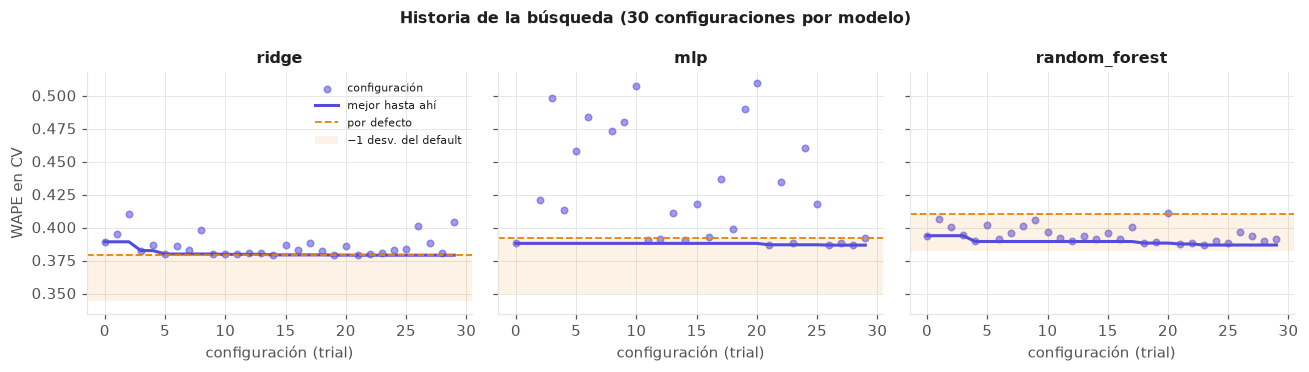

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (nombre, h) in zip(axes, historiales.items()):
    base = top3.set_index("tags.mlflow.runName").loc[nombre]
    ax.scatter(h.trial, h.cv_wape_mean, s=18, color=estilo.INDIGO, alpha=0.55, label="configuración")
    ax.plot(h.trial, h.cv_wape_mean.cummin(), color=estilo.INDIGO, lw=2, label="mejor hasta ahí")
    ax.axhline(base["metrics.cv_wape_mean"], color=estilo.AMBAR, lw=1.2, ls="--", label="por defecto")
    ax.axhspan(base["metrics.cv_wape_mean"] - base["metrics.cv_wape_std"], base["metrics.cv_wape_mean"],
               color=estilo.AMBAR, alpha=0.10, lw=0, label="−1 desv. del default")
    ax.set(title=nombre, xlabel="configuración (trial)")
axes[0].set_ylabel("WAPE en CV"); axes[0].legend(fontsize=7.5, loc="upper right")
axes[0].set_ylim(top=min(0.55, max(h.cv_wape_mean.quantile(0.9) for h in historiales.values()) + 0.01))
fig.suptitle("Historia de la búsqueda (30 configuraciones por modelo)", fontweight="bold", fontsize=10.5)
fig.tight_layout(); estilo.guardar(fig, "tuning_historia"); plt.show()

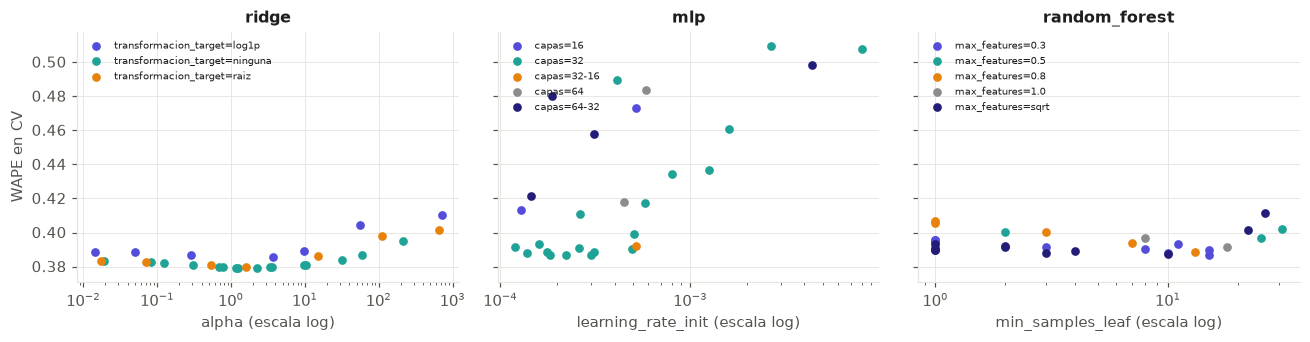

In [8]:
# El hiperparámetro que más mueve el resultado en cada modelo.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
claves = {"ridge": ("alpha", "transformacion_target"), "mlp": ("learning_rate_init", "capas"),
          "random_forest": ("min_samples_leaf", "max_features")}
for ax, (nombre, h) in zip(axes, historiales.items()):
    x, color_por = claves[nombre]
    niveles = sorted(h[color_por].astype(str).unique())
    paleta = [estilo.INDIGO, estilo.TEAL, estilo.AMBAR, estilo.GRIS, "#231d7a"]
    for i, nv in enumerate(niveles):
        s = h[h[color_por].astype(str) == nv]
        ax.scatter(s[x], s.cv_wape_mean, s=22, color=paleta[i % len(paleta)], label=f"{color_por}={nv}")
    ax.set_xscale("log"); ax.set(title=nombre, xlabel=x + " (escala log)")
    ax.legend(fontsize=6.5, loc="upper left")
axes[0].set_ylabel("WAPE en CV")
axes[0].set_ylim(top=min(0.55, max(h.cv_wape_mean.quantile(0.9) for h in historiales.values()) + 0.01))
fig.tight_layout(); estilo.guardar(fig, "tuning_parametros"); plt.show()

## Diagnóstico del tuning

**Ninguna mejora supera la desviación entre pliegues.** Con el criterio del PSet, ningún modelo mejoró:

- **Ridge:** +0,0003. El mejor `alpha` (≈ 1,2) es casi el valor por defecto (1,0). Las transformaciones log1p y raíz del target **no ayudaron**, así que la hipótesis del hallazgo H1 se descarta con evidencia: el WAPE trabaja en la escala original, y comprimir los picos los subestima aún más.
- **MLP:** +0,006 frente a una desviación de 0,043.
- **RandomForest:** +0,023 frente a 0,028. Es la mayor mejora y aparece en 4 de 5 pliegues, pero no cruza el umbral. Lo que el tuning sí logró fue **eliminar el sobreajuste**: con `max_depth` = 5 y `min_samples_leaf` = 15, la brecha cae de 0,27 a 0,02 y el costo de negocio de $221 a $209.

**Lectura.** El cuello de botella no es la capacidad del modelo ni sus hiperparámetros: son los datos. Hay 10 semanas de historia, y la variación entre semanas (±0,035 de WAPE) es mayor que cualquier diferencia entre configuraciones. Para la selección se usan las versiones **por defecto** (ver notebook 05).